# Handwritten Digit Recognition using MNIST

This notebook trains a fully connected neural network to classify handwritten digits from 0 to 9. It uses the built-in MNIST dataset and saves plots and the trained model.

**How to use:** Run each cell from top to bottom. Read the comments in the code as you go.

## Step 1 — Imports and setup
Import the libraries and create folders for results.

In [ ]:
"""
Project 1: Handwritten Digit Recognition using MNIST and a Neural Network
Beginner-friendly Python script.
Run in Google Colab or locally after installing requirements.
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)



## 1. Load the built-in MNIST dataset (60,000 train; 10,000 test)

In [ ]:
# 1. Load the built-in MNIST dataset (60,000 train; 10,000 test)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("Training images:", x_train.shape)
print("Test images:", x_test.shape)



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


## 2. Display examples

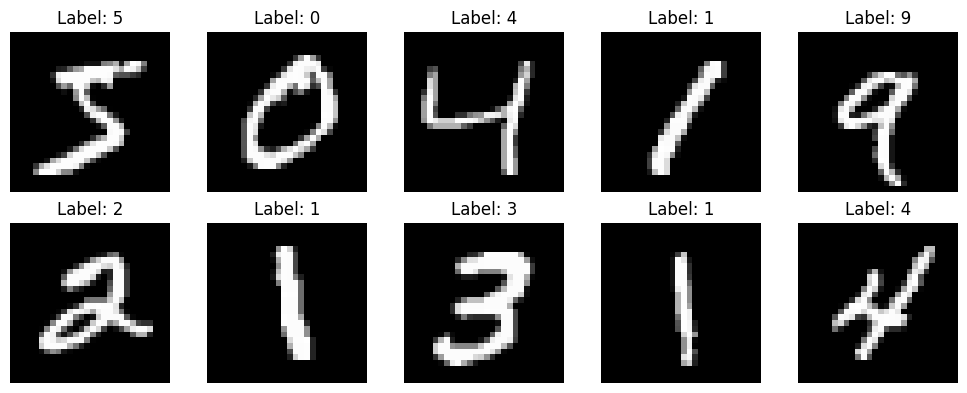

In [ ]:
# 2. Display examples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
fig.tight_layout()
fig.savefig("outputs/mnist_samples.png", dpi=150)
plt.show()



## 3. Preprocess: convert 0..255 pixel values to 0..1

In [ ]:
# 3. Preprocess: convert 0..255 pixel values to 0..1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0



## 4. Build a simple fully connected neural network

In [ ]:
# 4. Build a simple fully connected neural network
model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation="softmax")
])
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train (validation_split monitors learning; test set remains unseen until evaluation)

In [ ]:
# 5. Train (validation_split monitors learning; test set remains unseen until evaluation)
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)



Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8786 - loss: 0.4271 - val_accuracy: 0.9538 - val_loss: 0.1762
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9395 - loss: 0.2079 - val_accuracy: 0.9633 - val_loss: 0.1301
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9527 - loss: 0.1594 - val_accuracy: 0.9692 - val_loss: 0.1066
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9608 - loss: 0.1307 - val_accuracy: 0.9728 - val_loss: 0.0914
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9672 - loss: 0.1096 - val_accuracy: 0.9728 - val_loss: 0.0862


## 6. Evaluate on unseen test images

In [ ]:
# 6. Evaluate on unseen test images
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")



Test loss: 0.0972
Test accuracy: 97.08%


## 7. Save accuracy/loss plot

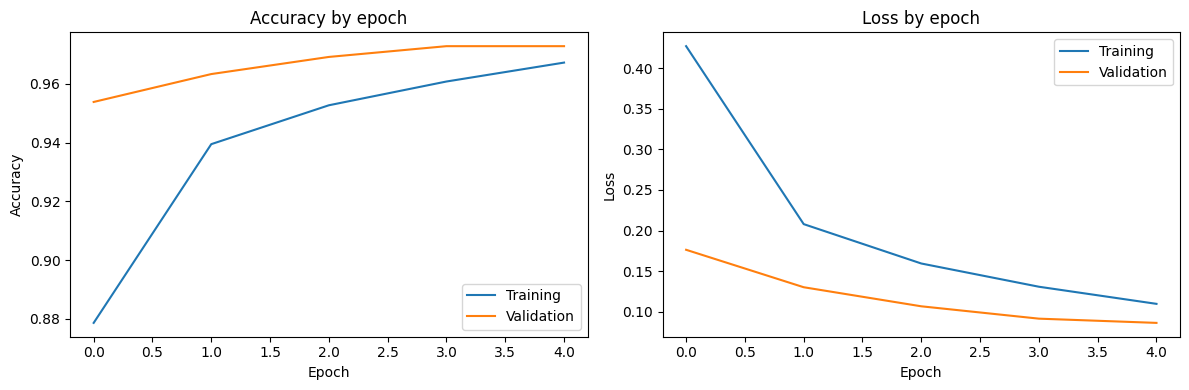

In [ ]:
# 7. Save accuracy/loss plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy by epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss by epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
fig.tight_layout()
fig.savefig("outputs/training_curves.png", dpi=150)
plt.show()



## 8. Predict all test images and print metrics

In [ ]:
# 8. Predict all test images and print metrics
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4))




Classification report:
              precision    recall  f1-score   support

           0     0.9778    0.9888    0.9833       980
           1     0.9851    0.9894    0.9873      1135
           2     0.9553    0.9729    0.9640      1032
           3     0.9507    0.9733    0.9618      1010
           4     0.9678    0.9807    0.9742       982
           5     0.9794    0.9585    0.9688       892
           6     0.9790    0.9739    0.9765       958
           7     0.9782    0.9601    0.9691      1028
           8     0.9526    0.9692    0.9608       974
           9     0.9834    0.9386    0.9604      1009

    accuracy                         0.9708     10000
   macro avg     0.9709    0.9705    0.9706     10000
weighted avg     0.9710    0.9708    0.9708     10000



## 9. Save confusion matrix image

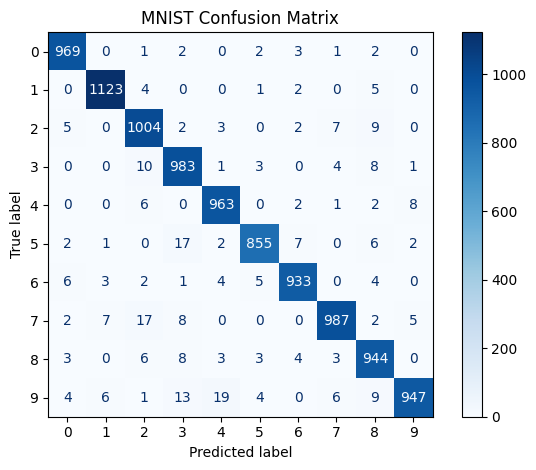

In [ ]:
# 9. Save confusion matrix image
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
plt.title("MNIST Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=150)
plt.show()



## 10. Show an example prediction

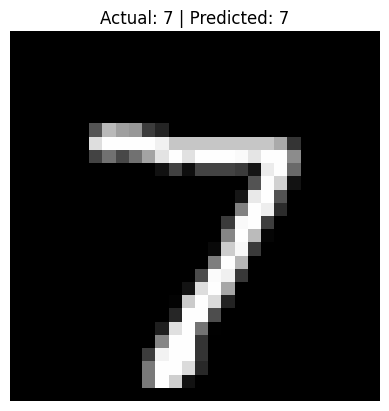

Actual digit: 7
Predicted digit: 7


In [ ]:
# 10. Show an example prediction
index = 0
plt.imshow(x_test[index], cmap="gray")
plt.title(f"Actual: {y_test[index]} | Predicted: {y_pred[index]}")
plt.axis("off")
plt.savefig("outputs/example_prediction.png", dpi=150)
plt.show()
print("Actual digit:", int(y_test[index]))
print("Predicted digit:", int(y_pred[index]))



## 11. Save the trained model

In [ ]:
# 11. Save the trained model
model.save("models/mnist_digit_model.keras")
print("Saved model to models/mnist_digit_model.keras")
print("Project finished. Check outputs/ for graphs and screenshots.")


Saved model to models/mnist_digit_model.keras
Project finished. Check outputs/ for graphs and screenshots.
